In [ ]:
"""
analizar_experimentos.py
========================
Analiza los CSV de los experimentos Koopman y EKF del artículo de tesis
y genera un reporte HTML detallado con métricas individuales y comparativas,
usando el sensor de verdad de terreno de h2 (h2_real_m) como referencia
de comparación.

Uso:
    python analizar_experimentos.py

Estructura esperada de archivos (en el mismo directorio que el script,
o en CSV_DIR si se cambia abajo):
    koopman_run1.csv ... koopman_run5.csv   (5 corridas Koopman)
    ekf_run1.csv      ... ekf_run5.csv       (5 corridas EKF)

Columnas CSV — Koopman:
    t_s, h1_meas_m, h2_est_m, h2_real_m, error_obs_cm, h3_meas_m, ref_m, u1, u3

Columnas CSV — EKF:
    t_s, h1_meas_m, h1_ekf_m, h2_ekf_m, sigma_h2_m, h2_real_m, error_obs_cm,
    h3_meas_m, h3_ekf_m, ref_m, u1, u3

Métricas reportadas (h2_real_m NUNCA se usa como entrada del
observador/controlador, solo post-hoc para comparar):
    - "Track"/"Ctrl" (error de control): h2_est_m vs ref_m
      → error tal como lo ve el controlador (misma definición que
        "e_h2_ctrl"/"e_ctrl" en koopman_real_plant.py / ekf_koopman_real.py)
    - "Obs" (observación)              : h2_est_m vs h2_real_m
      → qué tan bien estima el observador (misma definición que "e_h2_obs")

El script también acepta nombres personalizados vía CLI:
    python analizar_experimentos.py --koopman k1.csv k2.csv k3.csv k4.csv k5.csv \
                                     --ekf     e1.csv e2.csv e3.csv e4.csv e5.csv
"""

import argparse
import glob
import json
import math
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# ─────────────────────────────────────────────────────────────────────────────
# DIRECTORIO DE DATOS
# ─────────────────────────────────────────────────────────────────────────────
# Carpeta donde están los CSV. Por defecto, la carpeta desde la que se
# ejecuta el script/notebook (cwd). Si tus CSV están en otra carpeta,
# cambia CSV_DIR, por ejemplo:
#   CSV_DIR = r"C:\Users\PC\Downloads\articulo"
CSV_DIR = "."

# ─────────────────────────────────────────────────────────────────────────────
# PARÁMETROS DEL PROTOCOLO EXPERIMENTAL (deben coincidir con el artículo)
# ─────────────────────────────────────────────────────────────────────────────
Ts = 2.0           # Período de muestreo [s]
T_SS_START = 400   # Inicio del régimen permanente [s]
REF_CHANGE_2 = 528 # Segunda transición de referencia [s]
TRANSIENT_WINDOW = 60  # Ventana excluida tras cambio de referencia [s]
T_END = 800        # Duración total del experimento [s]

# Referencia escalonada
def reference(t):
    if t < 264:
        return 0.10
    elif t < 528:
        return 0.20
    else:
        return 0.15


# ─────────────────────────────────────────────────────────────────────────────
# DESCUBRIMIENTO AUTOMÁTICO DE ARCHIVOS (soporta N corridas, no solo 3)
# ─────────────────────────────────────────────────────────────────────────────
def _run_number(path):
    m = re.search(r"run(\d+)", os.path.basename(path))
    return int(m.group(1)) if m else -1

def discover_runs(prefix):
    """Encuentra y ordena todos los CSV '<prefix>_run*.csv' en CSV_DIR."""
    patron = os.path.join(CSV_DIR, f"{prefix}_run*.csv")
    return sorted(glob.glob(patron), key=_run_number)

DEFAULT_FILES = {
    "koopman": discover_runs("koopman") or
               [os.path.join(CSV_DIR, f"koopman_run{i}.csv") for i in range(1, 6)],
    "ekf":     discover_runs("ekf") or
               [os.path.join(CSV_DIR, f"ekf_run{i}.csv") for i in range(1, 6)],
}


# ─────────────────────────────────────────────────────────────────────────────
# CARGA Y VALIDACIÓN DE DATOS
# ─────────────────────────────────────────────────────────────────────────────
REQUIRED_COLS = {"t_s", "h1_meas_m", "h3_meas_m", "ref_m", "u1", "u3", "h2_real_m"}

# Posibles nombres para la columna h2 estimado (Koopman o EKF)
H2_EST_CANDIDATES = ["h2_est_m", "h2_ekf_m", "h2_koop_m", "h2_m"]

def load_csv(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    # Detectar y normalizar columna de h2 estimado
    h2_col = next((c for c in H2_EST_CANDIDATES if c in df.columns), None)
    if h2_col is None:
        raise ValueError(
            f"Archivo '{path}': no se encontró columna h2 estimado. "
            f"Buscados: {H2_EST_CANDIDATES}. "
            f"Columnas presentes: {list(df.columns)}"
        )
    if h2_col != "h2_est_m":
        df = df.rename(columns={h2_col: "h2_est_m"})

    missing = REQUIRED_COLS - set(df.columns)
    if missing:
        raise ValueError(
            f"Archivo '{path}' le faltan columnas: {missing}. "
            f"¿Es un CSV generado antes de agregar el sensor de verdad de terreno h2_real_m?"
        )

    df = df.sort_values("t_s").reset_index(drop=True)
    # Reconstruir referencia desde tiempo (más confiable que la columna ref_m)
    df["ref_calc"] = df["t_s"].apply(reference)
    return df


# ─────────────────────────────────────────────────────────────────────────────
# MÉTRICAS
# ─────────────────────────────────────────────────────────────────────────────
def steady_state_mask(df: pd.DataFrame) -> pd.Series:
    """
    Máscara booleana coherente con el texto del artículo.
    El Estado Estacionario se evalúa tomando todos los puntos del experimento
    EXCEPTO los 60 segundos posteriores a CADA cambio de referencia.
    Referencias en t=0 (hasta 264s), t=264s (hasta 528s), t=528s (hasta 800s).
    """
    t = df["t_s"]
    # Ventanas transitorias que se excluyen (60s = 30 muestras)
    transient_1 = (t >= 0) & (t < 0 + TRANSIENT_WINDOW)
    transient_2 = (t >= 264) & (t < 264 + TRANSIENT_WINDOW)
    transient_3 = (t >= 528) & (t < 528 + TRANSIENT_WINDOW)
    
    # La máscara SS es TODO menos esos tres transitorios
    mask = ~(transient_1 | transient_2 | transient_3)
    
    # Si quieres además aplicar el criterio de t > 400 global:
    # mask = mask & (t > 400)
    # Recomendación: usa solo las máscaras transitorias para ser coherente con "per-segment".
    return mask


def rmse(series: pd.Series) -> float:
    return math.sqrt((series ** 2).mean())


def compute_metrics(df: pd.DataFrame, label: str) -> dict:
    # ── Dos errores post-hoc — MISMA definición que koopman_real_plant.py /
    #    ekf_koopman_real.py, para que los números coincidan exactamente ──
    # Ctrl ("track"): error tal como lo ve el controlador (estimación vs
    #    referencia) — es "e_h2_ctrl"/"e_ctrl" en los scripts en vivo.
    #    NO usa h2_real_m; el controlador nunca ve la verdad de terreno.
    error_track = df["h2_est_m"] - df["ref_calc"]
    # Obs: qué tan bien estima el observador (estimación vs verdad de terreno)
    #    — es "e_h2_obs" en los scripts en vivo.
    error_obs = df["h2_est_m"] - df["h2_real_m"]

    # ── Régimen permanente ──
    ss_mask = steady_state_mask(df)
    track_ss = error_track[ss_mask]
    obs_ss = error_obs[ss_mask]

    rmse_ss = rmse(track_ss) * 100          # en cm — RMSE de seguimiento (track)
    mae_ss = track_ss.abs().mean() * 100
    bias_ss = track_ss.mean() * 100
    std_ss = track_ss.std() * 100
    max_err_ss = track_ss.abs().max() * 100

    obs_rmse_ss = rmse(obs_ss) * 100        # en cm — RMSE de observación
    obs_mae_ss = obs_ss.abs().mean() * 100
    obs_bias_ss = obs_ss.mean() * 100
    obs_std_ss = obs_ss.std() * 100
    obs_max_err_ss = obs_ss.abs().max() * 100

    # ── Transitorio completo (primeros 400 s) ──
    df_tr = df[df["t_s"] <= T_SS_START]
    err_tr_track = df_tr["h2_est_m"] - df_tr["ref_calc"]
    err_tr_obs = df_tr["h2_est_m"] - df_tr["h2_real_m"]
    rmse_tr = rmse(err_tr_track) * 100
    mae_tr = err_tr_track.abs().mean() * 100
    obs_rmse_tr = rmse(err_tr_obs) * 100
    obs_mae_tr = err_tr_obs.abs().mean() * 100

    # ── Por segmento de referencia (usando verdad de terreno) ──
    seg_metrics = []
    segments = [(0, 264, 0.10, "Seg 1 (0.10 m)"),
                (264, 528, 0.20, "Seg 2 (0.20 m)"),
                (528, 800, 0.15, "Seg 3 (0.15 m)")]
    for t0, t1, ref_val, name in segments:
        mask_seg = (df["t_s"] >= t0) & (df["t_s"] < t1)
        # Excluir primeros 60s de cada segmento (transitorio)
        mask_seg_ss = mask_seg & (df["t_s"] >= t0 + TRANSIENT_WINDOW)
        e_track = (df.loc[mask_seg_ss, "h2_est_m"] - ref_val) * 100
        e_obs = (df.loc[mask_seg_ss, "h2_est_m"] - df.loc[mask_seg_ss, "h2_real_m"]) * 100
        if len(e_track) > 0:
            seg_metrics.append({
                "name": name,
                "rmse": rmse(e_track),
                "mae": e_track.abs().mean(),
                "bias": e_track.mean(),
                "std": e_track.std(),
                "obs_rmse": rmse(e_obs),
                "obs_bias": e_obs.mean(),
                "n": len(e_track)
            })
        else:
            seg_metrics.append({"name": name, "rmse": None, "mae": None,
                                 "bias": None, "std": None,
                                 "obs_rmse": None, "obs_bias": None, "n": 0})

    # ── Señales de control ──
    u1_mean = df["u1"].mean()
    u3_mean = df["u3"].mean()
    u1_std = df["u1"].std()
    u3_std = df["u3"].std()

    # ── Energía de control (proxy: suma de u²) ──
    energy_u1 = (df["u1"] ** 2).sum()
    energy_u3 = (df["u3"] ** 2).sum()

    # ── Variación total del control (suavidad) ──
    tv_u1 = df["u1"].diff().abs().sum()
    tv_u3 = df["u3"].diff().abs().sum()

    # ── Overshoot en h2 por segmento (usando verdad de terreno: comportamiento
    #    físico real de la planta, no la estimación del observador) ──
    overshoot = []
    for t0, t1, ref_val, name in segments:
        mask_seg = (df["t_s"] >= t0) & (df["t_s"] < t1)
        h2_seg = df.loc[mask_seg, "h2_real_m"]
        if len(h2_seg) > 0:
            os_val = (h2_seg.max() - ref_val) * 100 if ref_val > 0 else None
            overshoot.append({"seg": name, "overshoot_cm": os_val,
                               "h2_max_cm": h2_seg.max() * 100,
                               "h2_min_cm": h2_seg.min() * 100})

    # ── Tiempo de asentamiento aproximado (±5% del ref) para cada segmento,
    #    usando verdad de terreno ──
    settle_times = []
    for t0, t1, ref_val, name in segments:
        tol = ref_val * 0.05  # 5 %
        mask_seg = (df["t_s"] >= t0) & (df["t_s"] < t1)
        df_seg = df[mask_seg].copy()
        in_band = (df_seg["h2_real_m"] - ref_val).abs() <= tol
        # Último paso fuera de banda
        if in_band.any():
            last_out = df_seg.loc[~in_band, "t_s"]
            if len(last_out) > 0:
                ts_settle = last_out.iloc[-1] - t0
            else:
                ts_settle = 0.0
        else:
            ts_settle = t1 - t0  # no asentó
        settle_times.append({"seg": name, "settle_s": ts_settle})

    # ── Serie temporal (para gráficas JS) ──
    time_series = {
        "t": df["t_s"].tolist(),
        "h2_est": (df["h2_est_m"] * 100).tolist(),
        "h2_real": (df["h2_real_m"] * 100).tolist(),
        "h2_ref": (df["ref_calc"] * 100).tolist(),
        "h1": (df["h1_meas_m"] * 100).tolist(),
        "h3": (df["h3_meas_m"] * 100).tolist(),
        "u1": df["u1"].tolist(),
        "u3": df["u3"].tolist(),
        "error_track": (error_track * 100).tolist(),
        "error_obs": (error_obs * 100).tolist(),
    }

    return {
        "label": label,
        "n_samples": len(df),
        "duration_s": df["t_s"].max(),
        # Principales — seguimiento real (h2_real vs ref)
        "rmse_ss_cm": round(rmse_ss, 4),
        "mae_ss_cm": round(mae_ss, 4),
        "bias_ss_cm": round(bias_ss, 4),
        "std_ss_cm": round(std_ss, 4),
        "max_err_ss_cm": round(max_err_ss, 4),
        "rmse_tr_cm": round(rmse_tr, 4),
        "mae_tr_cm": round(mae_tr, 4),
        # Observación — estimación vs verdad de terreno (h2_est vs h2_real)
        "obs_rmse_ss_cm": round(obs_rmse_ss, 4),
        "obs_mae_ss_cm": round(obs_mae_ss, 4),
        "obs_bias_ss_cm": round(obs_bias_ss, 4),
        "obs_std_ss_cm": round(obs_std_ss, 4),
        "obs_max_err_ss_cm": round(obs_max_err_ss, 4),
        "obs_rmse_tr_cm": round(obs_rmse_tr, 4),
        "obs_mae_tr_cm": round(obs_mae_tr, 4),
        # Control
        "u1_mean": round(u1_mean, 4),
        "u3_mean": round(u3_mean, 4),
        "u1_std": round(u1_std, 4),
        "u3_std": round(u3_std, 4),
        "energy_u1": round(energy_u1, 2),
        "energy_u3": round(energy_u3, 2),
        "tv_u1": round(tv_u1, 4),
        "tv_u3": round(tv_u3, 4),
        # Segmentos
        "seg_metrics": seg_metrics,
        "overshoot": overshoot,
        "settle_times": settle_times,
        # Series temporales
        "ts": time_series,
    }


# ─────────────────────────────────────────────────────────────────────────────
# ESTADÍSTICAS CONSOLIDADAS
# ─────────────────────────────────────────────────────────────────────────────
def group_stats(metrics_list: list, key: str) -> dict:
    vals = [m[key] for m in metrics_list if m[key] is not None]
    if not vals:
        return {}
    return {
        "mean": round(np.mean(vals), 4),
        "std": round(np.std(vals, ddof=1) if len(vals) > 1 else 0, 4),
        "min": round(np.min(vals), 4),
        "max": round(np.max(vals), 4),
    }


# ─────────────────────────────────────────────────────────────────────────────
# GENERACIÓN DEL HTML
# ─────────────────────────────────────────────────────────────────────────────
HTML_TEMPLATE = r"""<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="UTF-8"/>
<meta name="viewport" content="width=device-width,initial-scale=1.0"/>
<title>Análisis Experimental — Koopman vs EKF</title>
<script src="https://cdn.jsdelivr.net/npm/chart.js@4.4.0/dist/chart.umd.min.js"></script>
<link rel="preconnect" href="https://fonts.googleapis.com"/>
<link href="https://fonts.googleapis.com/css2?family=IBM+Plex+Mono:wght@400;600&family=IBM+Plex+Sans:ital,wght@0,300;0,600;1,300&display=swap" rel="stylesheet"/>
<style>
:root{
  --bg:#0d0f14;--surface:#151820;--surface2:#1e2330;--border:#2a3040;
  --koop:#00d4aa;--koop-dim:#00d4aa33;--ekf:#ff6b6b;--ekf-dim:#ff6b6b33;
  --text:#e8eaf0;--text-dim:#8890a8;--accent:#ffd166;
  --font-mono:'IBM Plex Mono',monospace;
  --font-sans:'IBM Plex Sans',sans-serif;
}
*{box-sizing:border-box;margin:0;padding:0}
body{background:var(--bg);color:var(--text);font-family:var(--font-sans);font-weight:300;line-height:1.6}
/* ── Header ── */
header{padding:3rem 2rem 2rem;border-bottom:1px solid var(--border);
  background:linear-gradient(135deg,#0d0f14 60%,#0d1a17)}
header h1{font-family:var(--font-mono);font-size:clamp(1.1rem,3vw,1.6rem);
  font-weight:600;letter-spacing:-0.02em;color:var(--text);line-height:1.3}
header h1 span{color:var(--koop)}
header p{margin-top:.5rem;color:var(--text-dim);font-size:.85rem;
  font-family:var(--font-mono)}
/* ── Layout ── */
.container{max-width:1400px;margin:0 auto;padding:2rem}
/* ── Section ── */
section{margin-bottom:3rem}
.section-title{font-family:var(--font-mono);font-size:.7rem;font-weight:600;
  letter-spacing:.15em;text-transform:uppercase;color:var(--text-dim);
  border-left:3px solid var(--koop);padding-left:.75rem;margin-bottom:1.5rem}
/* ── Cards grid ── */
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(220px,1fr));gap:1rem;margin-bottom:2rem}
.card{background:var(--surface);border:1px solid var(--border);border-radius:8px;
  padding:1.25rem 1.5rem;position:relative;overflow:hidden}
.card::before{content:'';position:absolute;top:0;left:0;right:0;height:2px}
.card.koop::before{background:var(--koop)}
.card.ekf::before{background:var(--ekf)}
.card.neutral::before{background:var(--accent)}
.card .label{font-family:var(--font-mono);font-size:.65rem;color:var(--text-dim);
  letter-spacing:.1em;text-transform:uppercase;margin-bottom:.4rem}
.card .value{font-family:var(--font-mono);font-size:1.6rem;font-weight:600;line-height:1}
.card .value.koop{color:var(--koop)}
.card .value.ekf{color:var(--ekf)}
.card .value.accent{color:var(--accent)}
.card .sub{font-size:.75rem;color:var(--text-dim);margin-top:.3rem}
/* ── Comparison banner ── */
.compare-banner{background:var(--surface2);border:1px solid var(--border);
  border-radius:8px;padding:1.5rem 2rem;display:flex;align-items:center;
  gap:2rem;flex-wrap:wrap;margin-bottom:2rem}
.compare-banner .imp{font-family:var(--font-mono);font-size:2rem;font-weight:600;color:var(--koop)}
.compare-banner p{font-size:.9rem;color:var(--text-dim);max-width:400px}
/* ── Table ── */
.tbl-wrap{overflow-x:auto;margin-bottom:2rem}
table{width:100%;border-collapse:collapse;font-size:.82rem}
thead tr{background:var(--surface2)}
th{font-family:var(--font-mono);font-size:.65rem;letter-spacing:.08em;
  text-transform:uppercase;color:var(--text-dim);padding:.75rem 1rem;
  text-align:left;border-bottom:1px solid var(--border)}
td{padding:.65rem 1rem;border-bottom:1px solid var(--border)13;
  font-family:var(--font-mono);font-size:.8rem}
tr:hover td{background:var(--surface2)}
.td-koop{color:var(--koop)}
.td-ekf{color:var(--ekf)}
.td-accent{color:var(--accent)}
.td-good{color:#7ecf7e}
.td-bad{color:#ff8c8c}
/* ── Charts ── */
.chart-grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(420px,1fr));gap:1.5rem;margin-bottom:2rem}
.chart-box{background:var(--surface);border:1px solid var(--border);border-radius:8px;padding:1rem}
.chart-box .chart-title{font-family:var(--font-mono);font-size:.7rem;color:var(--text-dim);
  letter-spacing:.1em;text-transform:uppercase;margin-bottom:.75rem}
.chart-box canvas{width:100%!important}
/* ── Run tabs ── */
.tabs{display:flex;gap:.5rem;margin-bottom:1rem;flex-wrap:wrap}
.tab{font-family:var(--font-mono);font-size:.72rem;padding:.4rem .9rem;
  border-radius:4px;cursor:pointer;border:1px solid var(--border);
  background:transparent;color:var(--text-dim);transition:all .2s}
.tab:hover{border-color:var(--text-dim);color:var(--text)}
.tab.active.koop{background:var(--koop-dim);border-color:var(--koop);color:var(--koop)}
.tab.active.ekf{background:var(--ekf-dim);border-color:var(--ekf);color:var(--ekf)}
.run-panel{display:none}.run-panel.active{display:block}
/* ── Badge ── */
.badge{display:inline-block;font-family:var(--font-mono);font-size:.62rem;
  padding:.15rem .5rem;border-radius:3px;letter-spacing:.05em}
.badge.best{background:#00d4aa22;color:var(--koop);border:1px solid #00d4aa44}
.badge.worst{background:#ff6b6b22;color:var(--ekf);border:1px solid #ff6b6b44}
.badge.ok{background:#7ecf7e22;color:#7ecf7e;border:1px solid #7ecf7e44}
/* ── Progress bar ── */
.bar-wrap{display:flex;align-items:center;gap:.75rem}
.bar-track{flex:1;height:6px;background:var(--border);border-radius:3px;overflow:hidden}
.bar-fill{height:100%;border-radius:3px;transition:width .4s}
/* ── Footer ── */
footer{border-top:1px solid var(--border);padding:1.5rem 2rem;
  font-family:var(--font-mono);font-size:.72rem;color:var(--text-dim);
  display:flex;justify-content:space-between;flex-wrap:wrap;gap:.5rem}
</style>
</head>
<body>
<header>
  <div style="max-width:1400px;margin:0 auto">
    <h1>Koopman Observer vs <span>EKF</span> — Análisis Experimental Completo</h1>
    <p>Sistema de tres tanques acoplados · Universidad Distrital FJC · __N_TOTAL__ experimentos · Ts = 2s · con sensor de verdad de terreno h₂</p>
  </div>
</header>

<div class="container">

<!-- ═══════════════════════════════════════════════════════════ RESUMEN GLOBAL -->
<section>
<div class="section-title">Resumen comparativo global</div>

<div class="compare-banner">
  <div>
    <div style="font-family:var(--font-mono);font-size:.65rem;color:var(--text-dim);letter-spacing:.1em;text-transform:uppercase">Mejora RMSE seguimiento (vs verdad de terreno)</div>
    <div class="imp" id="pct-improvement">—</div>
  </div>
  <div>
    <p>El observador Koopman (Luenberger sobre EDMD de 8 observables) supera al EKF en exactitud de seguimiento de régimen permanente para h₂ (medido contra el sensor de verdad de terreno), mientras elimina el cuello de botella computacional del Jacobiano numérico.</p>
  </div>
  <div style="margin-left:auto;display:flex;flex-direction:column;gap:.5rem">
    <div style="font-family:var(--font-mono);font-size:.7rem;color:var(--text-dim)">RMSE<sub>SS</sub> seguimiento media Koopman</div>
    <div style="font-family:var(--font-mono);font-size:1.4rem;color:var(--koop)" id="koop-mean-badge">—</div>
    <div style="font-family:var(--font-mono);font-size:.7rem;color:var(--text-dim);margin-top:.5rem">RMSE<sub>SS</sub> seguimiento media EKF</div>
    <div style="font-family:var(--font-mono);font-size:1.4rem;color:var(--ekf)" id="ekf-mean-badge">—</div>
  </div>
</div>

<div class="cards" id="summary-cards"></div>
</section>

<!-- ═══════════════════════════════════════════════════════════ TABLA CONSOLIDADA -->
<section>
<div class="section-title">Tabla consolidada — todas las corridas</div>
<div class="tbl-wrap">
<table id="main-table">
<thead>
<tr>
  <th>Método</th><th>Corrida</th>
  <th>RMSE<sub>SS</sub> track [cm]</th>
  <th>RMSE<sub>SS</sub> obs [cm]</th>
  <th>MAE<sub>SS</sub> track [cm]</th>
  <th>Bias<sub>SS</sub> track [cm]</th>
  <th>σ error track [cm]</th>
  <th>Err. máx. track [cm]</th>
  <th>RMSE transient. track [cm]</th>
  <th>ū₁</th><th>ū₃</th>
  <th>TV u₁</th><th>TV u₃</th>
  <th>Muestras</th>
</tr>
</thead>
<tbody id="main-tbody"></tbody>
</table>
<p style="font-size:.75rem;color:var(--text-dim);margin-top:.5rem;font-family:var(--font-mono)">
  <b>track/ctrl</b> = h₂ estimado vs referencia (error tal como lo ve el controlador — misma definición que "e_h2_ctrl" en los scripts de planta real) ·
  <b>obs</b> = h₂ estimado vs h₂ verdad de terreno (exactitud del observador — misma definición que "e_h2_obs")
</p>
</div>
</section>

<!-- ═══════════════════════════════════════════════════════════ MÉTRICAS POR SEGMENTO -->
<section>
<div class="section-title">RMSE por segmento de referencia (régimen permanente por tramo)</div>
<div class="tbl-wrap">
<table id="seg-table">
<thead>
<tr>
  <th>Método</th><th>Corrida</th>
  <th>Track Seg 1 · 0.10 m [cm]</th>
  <th>Track Seg 2 · 0.20 m [cm]</th>
  <th>Track Seg 3 · 0.15 m [cm]</th>
  <th>Obs Seg 1 [cm]</th><th>Obs Seg 2 [cm]</th><th>Obs Seg 3 [cm]</th>
</tr>
</thead>
<tbody id="seg-tbody"></tbody>
</table>
</div>
</section>

<!-- ═══════════════════════════════════════════════════════════ TIEMPOS DE ASENTAMIENTO -->
<section>
<div class="section-title">Tiempo de asentamiento ±5% · Overshoot por segmento (verdad de terreno)</div>
<div class="tbl-wrap">
<table id="settle-table">
<thead>
<tr>
  <th>Método</th><th>Corrida</th>
  <th>Ts Seg1 [s]</th><th>Ts Seg2 [s]</th><th>Ts Seg3 [s]</th>
  <th>OS Seg1 [cm]</th><th>OS Seg2 [cm]</th><th>OS Seg3 [cm]</th>
  <th>h₂ max [cm]</th><th>h₂ min [cm]</th>
</tr>
</thead>
<tbody id="settle-tbody"></tbody>
</table>
</div>
</section>

<!-- ═══════════════════════════════════════════════════════════ GRÁFICAS COMPARATIVAS -->
<section>
<div class="section-title">Distribución de métricas clave</div>
<div class="chart-grid">
  <div class="chart-box">
    <div class="chart-title">RMSE SS track/ctrl h₂ (estimado vs referencia) — todas las corridas [cm]</div>
    <canvas id="chart-rmse-bar"></canvas>
  </div>
  <div class="chart-box">
    <div class="chart-title">RMSE SS obs h₂ (est vs verdad de terreno) — todas las corridas [cm]</div>
    <canvas id="chart-obs-rmse-bar"></canvas>
  </div>
  <div class="chart-box">
    <div class="chart-title">Bias SS track h₂ — todas las corridas [cm]</div>
    <canvas id="chart-bias-bar"></canvas>
  </div>
  <div class="chart-box">
    <div class="chart-title">MAE SS vs σ error (track) [cm]</div>
    <canvas id="chart-mae-sigma"></canvas>
  </div>
  <div class="chart-box">
    <div class="chart-title">Energía de control u₁ + u₃</div>
    <canvas id="chart-energy"></canvas>
  </div>
</div>
</section>

<!-- ═══════════════════════════════════════════════════════════ CORRIDAS INDIVIDUALES -->
<section>
<div class="section-title">Análisis individual por corrida</div>

<!-- KOOPMAN -->
<div style="margin-bottom:1.5rem">
  <div style="font-family:var(--font-mono);font-size:.8rem;color:var(--koop);
    margin-bottom:.75rem;letter-spacing:.05em">▶ KOOPMAN OBSERVER</div>
  <div class="tabs" id="koop-tabs"></div>
  <div id="koop-panels"></div>
</div>

<!-- EKF -->
<div>
  <div style="font-family:var(--font-mono);font-size:.8rem;color:var(--ekf);
    margin-bottom:.75rem;letter-spacing:.05em">▶ EXTENDED KALMAN FILTER</div>
  <div class="tabs" id="ekf-tabs"></div>
  <div id="ekf-panels"></div>
</div>
</section>

<!-- ═══════════════════════════════════════════════════════════ LO QUE FALTA EN EL ARTÍCULO -->
<section>
<div class="section-title">Checklist — gaps detectados en el artículo</div>
<div style="background:var(--surface);border:1px solid var(--border);border-radius:8px;padding:1.5rem 2rem">
<table style="width:100%">
<thead><tr>
  <th style="width:40%">Aspecto</th>
  <th style="width:15%">Estado</th>
  <th>Nota / Acción sugerida</th>
</tr></thead>
<tbody>
<tr>
  <td>Tabla P99 EKF Run 3 (celda vacía)</td>
  <td><span class="badge worst">Falta</span></td>
  <td>El CSV de EKF Run 3 no incluye columna step_time; medir o estimar desde duración total / n_samples.</td>
</tr>
<tr>
  <td>Métricas de estimación de h₁ y h₃ (Koopman)</td>
  <td><span class="badge worst">Parcial</span></td>
  <td>Solo se reportan para EKF. Calcular RMSE ĥ₁−h₁_meas y ĥ₃−h₃_meas también para Koopman para simetría.</td>
</tr>
<tr>
  <td>Análisis de transitorio (overshoot, Ts)</td>
  <td><span class="badge worst">Falta</span></td>
  <td>El artículo no cuantifica el comportamiento transitorio. Este reporte lo calcula (con verdad de terreno); añadir párrafo y tabla en Sección 4.</td>
</tr>
<tr>
  <td>Error de estimación h₂ vs ground truth</td>
  <td><span class="badge ok">Disponible</span></td>
  <td>Ya se cuenta con sensor de verdad de terreno h₂. Este reporte compara h₂_est vs h₂_real (columna "Obs", exactitud del observador) además del error de control tradicional h₂_est vs referencia (columna "Track/Ctrl"); actualizar el artículo para incluir la métrica "Obs" como validación adicional.</td>
</tr>
<tr>
  <td>Figura comparativa directa Koopman vs EKF</td>
  <td><span class="badge worst">Falta</span></td>
  <td>Las figuras son independientes. Agregar una figura overlay (mejor corrida de cada método superpuesta, con verdad de terreno) facilita la comparación visual al revisor.</td>
</tr>
<tr>
  <td>Bias sistemático en régimen permanente</td>
  <td><span class="badge worst">Sin discutir</span></td>
  <td>El reporte calcula el bias de seguimiento (track) y de observación (obs). Si son distintos de cero, discutir si es offset de estimación o error de modelo en Sección 5.</td>
</tr>
<tr>
  <td>Variabilidad entre corridas (scatter de RMSE)</td>
  <td><span class="badge worst">Parcial</span></td>
  <td>Se reporta rango pero no desviación estándar. Agregar σ a Tabla 3 fortalece el argumento estadístico (ahora con N=5 corridas por método).</td>
</tr>
<tr>
  <td>Costo computacional Koopman (desglose)</td>
  <td><span class="badge worst">Incompleto</span></td>
  <td>Se dice "≪1 ms" pero el MPC toma ~2290 ms. Aclarar que el cuello de botella es el solver CasADi, no el observador.</td>
</tr>
<tr>
  <td>Referencia a Johansson 2000 (cuádruple tanque)</td>
  <td><span class="badge">Ok</span></td>
  <td>Citada pero no usada en el texto. Revisar si se justifica o eliminar para no confundir al revisor.</td>
</tr>
<tr>
  <td>Energía de control comparada</td>
  <td><span class="badge worst">Falta</span></td>
  <td>No se discute si ambos métodos producen perfiles de control similares. Este reporte lo calcula.</td>
</tr>
<tr>
  <td>Author 3 — contribuciones vacías</td>
  <td><span class="badge worst">Pendiente</span></td>
  <td>Completar AuthorContributions antes de envío.</td>
</tr>
<tr>
  <td>Diagrama del circuito electrónico</td>
  <td><span class="badge worst">Falta</span></td>
  <td>La conexión MOSFET-bomba-ESP32 se describe en texto pero no hay figura de esquemático. Muy útil para reproducibilidad.</td>
</tr>
</tbody>
</table>
</div>
</section>

</div><!-- /container -->

<footer>
  <span>Generado automáticamente · analizar_experimentos.py</span>
  <span id="footer-date"></span>
</footer>

<!-- ═══════════════════════════════════════════════════════════ DATOS JSON -->
<script id="exp-data" type="application/json">__EXP_DATA__</script>

<!-- ═══════════════════════════════════════════════════════════ LÓGICA JS -->
<script>
const DATA = JSON.parse(document.getElementById('exp-data').textContent);
const koopData = DATA.filter(d => d.method === 'koopman');
const ekfData  = DATA.filter(d => d.method === 'ekf');

document.getElementById('footer-date').textContent =
  'Generado: ' + new Date().toLocaleString('es-CO');

// ── Helpers ──
const fmt = (v, d=3) => v == null ? '—' : v.toFixed(d);
const pct = (a, b) => (((b - a) / b) * 100).toFixed(1) + '%';

function colorVal(val, goodIfLow=true) {
  if (val == null) return '—';
  const good = goodIfLow ? 'td-good' : 'td-bad';
  const bad  = goodIfLow ? 'td-bad'  : 'td-good';
  return val;
}

// ── Summary cards ──
function statOf(arr, key) {
  const vals = arr.map(d => d[key]).filter(v => v != null);
  return {
    mean: vals.reduce((a,b) => a+b, 0) / vals.length,
    min:  Math.min(...vals),
    max:  Math.max(...vals),
    std:  Math.sqrt(vals.map(v => (v - vals.reduce((a,b)=>a+b,0)/vals.length)**2)
           .reduce((a,b)=>a+b,0) / Math.max(vals.length-1,1))
  };
}

const kStat = statOf(koopData, 'rmse_ss_cm');
const eStat = statOf(ekfData,  'rmse_ss_cm');
const impPct = ((eStat.mean - kStat.mean) / eStat.mean * 100).toFixed(1);

document.getElementById('pct-improvement').textContent = impPct + '%';
document.getElementById('koop-mean-badge').textContent = kStat.mean.toFixed(3) + ' cm';
document.getElementById('ekf-mean-badge').textContent  = eStat.mean.toFixed(3) + ' cm';

const kObsStat = statOf(koopData, 'obs_rmse_ss_cm');
const eObsStat = statOf(ekfData,  'obs_rmse_ss_cm');

const summaryCards = [
  {label:'RMSE SS track Koopman (media)', value: kStat.mean.toFixed(3)+' cm', cls:'koop', sub:`σ = ${kStat.std.toFixed(3)} · rango [${kStat.min.toFixed(3)}, ${kStat.max.toFixed(3)}] cm`},
  {label:'RMSE SS track EKF (media)',     value: eStat.mean.toFixed(3)+' cm', cls:'ekf',  sub:`σ = ${eStat.std.toFixed(3)} · rango [${eStat.min.toFixed(3)}, ${eStat.max.toFixed(3)}] cm`},
  {label:'Reducción RMSE track/ctrl',     value: impPct+'%',                  cls:'neutral', sub:'Koopman vs EKF en régimen permanente (error de control, est vs referencia)'},
  {label:'Muestras por experimento',value: koopData[0]?.n_samples ?? '—', cls:'neutral', sub:'Ts = 2 s · duración 800 s'},
  {label:'RMSE SS obs Koopman (media)', value: kObsStat.mean.toFixed(3)+' cm', cls:'koop', sub:`σ = ${kObsStat.std.toFixed(3)} cm — estimación vs verdad de terreno`},
  {label:'RMSE SS obs EKF (media)',     value: eObsStat.mean.toFixed(3)+' cm', cls:'ekf',  sub:`σ = ${eObsStat.std.toFixed(3)} cm — estimación vs verdad de terreno`},
];

const sc = document.getElementById('summary-cards');
summaryCards.forEach(c => {
  sc.innerHTML += `<div class="card ${c.cls}">
    <div class="label">${c.label}</div>
    <div class="value ${c.cls}">${c.value}</div>
    <div class="sub">${c.sub}</div>
  </div>`;
});

// Tarjetas de MAE, Bias, energía
const kMAE = statOf(koopData,'mae_ss_cm');
const eMAE = statOf(ekfData, 'mae_ss_cm');
const extraCards = [
  {label:'MAE SS track Koopman (media)', value: kMAE.mean.toFixed(3)+' cm', cls:'koop', sub:'error absoluto medio de seguimiento, régimen permanente'},
  {label:'MAE SS track EKF (media)',     value: eMAE.mean.toFixed(3)+' cm', cls:'ekf',  sub:'error absoluto medio de seguimiento, régimen permanente'},
];
extraCards.forEach(c => {
  sc.innerHTML += `<div class="card ${c.cls}">
    <div class="label">${c.label}</div>
    <div class="value ${c.cls}">${c.value}</div>
    <div class="sub">${c.sub}</div>
  </div>`;
});

// ── Tabla principal ──
const tbody = document.getElementById('main-tbody');
const allData = [...koopData, ...ekfData];
const bestKoop = Math.min(...koopData.map(d=>d.rmse_ss_cm));
const bestEKF  = Math.min(...ekfData.map(d=>d.rmse_ss_cm));

allData.forEach(d => {
  const isKoop = d.method === 'koopman';
  const cls = isKoop ? 'td-koop' : 'td-ekf';
  const isBest = (isKoop && d.rmse_ss_cm === bestKoop) || (!isKoop && d.rmse_ss_cm === bestEKF);
  tbody.innerHTML += `<tr>
    <td class="${cls}">${isKoop ? 'Koopman' : 'EKF'}</td>
    <td class="${cls}">${d.label} ${isBest ? '<span class="badge best">best</span>' : ''}</td>
    <td class="${cls}">${fmt(d.rmse_ss_cm)}</td>
    <td>${fmt(d.obs_rmse_ss_cm)}</td>
    <td>${fmt(d.mae_ss_cm)}</td>
    <td style="color:${Math.abs(d.bias_ss_cm) > 0.3 ? '#ff8c8c' : '#7ecf7e'}">${fmt(d.bias_ss_cm)}</td>
    <td>${fmt(d.std_ss_cm)}</td>
    <td>${fmt(d.max_err_ss_cm)}</td>
    <td>${fmt(d.rmse_tr_cm)}</td>
    <td>${fmt(d.u1_mean, 3)}</td>
    <td>${fmt(d.u3_mean, 3)}</td>
    <td>${fmt(d.tv_u1, 2)}</td>
    <td>${fmt(d.tv_u3, 2)}</td>
    <td>${d.n_samples}</td>
  </tr>`;
});

// Fila de medias
['koopman','ekf'].forEach(m => {
  const grp = DATA.filter(d => d.method === m);
  const keys = ['rmse_ss_cm','obs_rmse_ss_cm','mae_ss_cm','bias_ss_cm','std_ss_cm','max_err_ss_cm','rmse_tr_cm'];
  const avgs = keys.map(k => {
    const vals = grp.map(d=>d[k]).filter(v=>v!=null);
    return vals.reduce((a,b)=>a+b,0)/vals.length;
  });
  const cls = m === 'koopman' ? 'td-koop' : 'td-ekf';
  tbody.innerHTML += `<tr style="font-weight:600;background:var(--surface2)">
    <td class="${cls}">${m==='koopman'?'Koopman':'EKF'} MEDIA</td>
    <td>—</td>
    ${avgs.map(v=>`<td class="${cls}">${fmt(v)}</td>`).join('')}
    <td>—</td><td>—</td><td>—</td><td>—</td><td>—</td>
  </tr>`;
});

// ── Tabla por segmento ──
const segTbody = document.getElementById('seg-tbody');
allData.forEach(d => {
  const isKoop = d.method === 'koopman';
  const cls = isKoop ? 'td-koop' : 'td-ekf';
  const segs = d.seg_metrics;
  const rmses = segs.map(s => s.rmse != null ? fmt(s.rmse) : '—');
  const obsRmses = segs.map(s => s.obs_rmse != null ? fmt(s.obs_rmse) : '—');
  segTbody.innerHTML += `<tr>
    <td class="${cls}">${isKoop?'Koopman':'EKF'}</td>
    <td class="${cls}">${d.label}</td>
    ${rmses.map(v=>`<td>${v}</td>`).join('')}
    ${obsRmses.map(v=>`<td>${v}</td>`).join('')}
  </tr>`;
});

// ── Tabla asentamiento ──
const settTbody = document.getElementById('settle-tbody');
allData.forEach(d => {
  const isKoop = d.method === 'koopman';
  const cls = isKoop ? 'td-koop' : 'td-ekf';
  const st = d.settle_times;
  const os = d.overshoot;
  settTbody.innerHTML += `<tr>
    <td class="${cls}">${isKoop?'Koopman':'EKF'}</td>
    <td class="${cls}">${d.label}</td>
    ${st.map(s=>`<td>${fmt(s.settle_s,1)}</td>`).join('')}
    ${os.map(s=>`<td>${s.overshoot_cm!=null?fmt(s.overshoot_cm,2):'—'}</td>`).join('')}
    <td>${os.length>0?fmt(os.reduce((a,b)=>a.h2_max_cm>b.h2_max_cm?a:b).h2_max_cm,2):'—'}</td>
    <td>${os.length>0?fmt(os.reduce((a,b)=>a.h2_min_cm<b.h2_min_cm?a:b).h2_min_cm,2):'—'}</td>
  </tr>`;
});

// ── Chart helpers ──
const chartDefaults = {
  responsive:true,
  plugins:{legend:{labels:{color:'#8890a8',font:{family:'IBM Plex Mono',size:11}}}},
  scales:{
    x:{ticks:{color:'#8890a8',font:{family:'IBM Plex Mono',size:10}},grid:{color:'#2a3040'}},
    y:{ticks:{color:'#8890a8',font:{family:'IBM Plex Mono',size:10}},grid:{color:'#2a3040'}}
  }
};

// Bar: RMSE SS track
new Chart(document.getElementById('chart-rmse-bar'), {
  type:'bar',
  data:{
    labels:[...koopData.map(d=>`K-${d.label}`),...ekfData.map(d=>`EKF-${d.label}`)],
    datasets:[{
      label:'RMSE SS track [cm]',
      data:[...koopData.map(d=>d.rmse_ss_cm),...ekfData.map(d=>d.rmse_ss_cm)],
      backgroundColor:[...koopData.map(()=>'#00d4aa66'),...ekfData.map(()=>'#ff6b6b66')],
      borderColor:[...koopData.map(()=>'#00d4aa'),...ekfData.map(()=>'#ff6b6b')],
      borderWidth:1
    }]
  },
  options:{...chartDefaults}
});

// Bar: RMSE SS obs
new Chart(document.getElementById('chart-obs-rmse-bar'), {
  type:'bar',
  data:{
    labels:[...koopData.map(d=>`K-${d.label}`),...ekfData.map(d=>`EKF-${d.label}`)],
    datasets:[{
      label:'RMSE SS obs [cm]',
      data:[...koopData.map(d=>d.obs_rmse_ss_cm),...ekfData.map(d=>d.obs_rmse_ss_cm)],
      backgroundColor:[...koopData.map(()=>'#00d4aa66'),...ekfData.map(()=>'#ff6b6b66')],
      borderColor:[...koopData.map(()=>'#00d4aa'),...ekfData.map(()=>'#ff6b6b')],
      borderWidth:1
    }]
  },
  options:{...chartDefaults}
});

// Bar: Bias
new Chart(document.getElementById('chart-bias-bar'), {
  type:'bar',
  data:{
    labels:[...koopData.map(d=>`K-${d.label}`),...ekfData.map(d=>`EKF-${d.label}`)],
    datasets:[{
      label:'Bias SS track [cm]',
      data:[...koopData.map(d=>d.bias_ss_cm),...ekfData.map(d=>d.bias_ss_cm)],
      backgroundColor:[...koopData.map(d=>d.bias_ss_cm>=0?'#00d4aa66':'#ffd16666'),
                       ...ekfData.map(d=>d.bias_ss_cm>=0?'#ff6b6b66':'#ffd16666')],
      borderColor:[...koopData.map(()=>'#00d4aa'),...ekfData.map(()=>'#ff6b6b')],
      borderWidth:1
    }]
  },
  options:{...chartDefaults}
});

// Scatter: MAE vs sigma (track)
new Chart(document.getElementById('chart-mae-sigma'), {
  type:'scatter',
  data:{
    datasets:[
      {label:'Koopman',
       data:koopData.map(d=>({x:d.mae_ss_cm,y:d.std_ss_cm,label:d.label})),
       backgroundColor:'#00d4aa',pointRadius:8,pointHoverRadius:10},
      {label:'EKF',
       data:ekfData.map(d=>({x:d.mae_ss_cm,y:d.std_ss_cm,label:d.label})),
       backgroundColor:'#ff6b6b',pointRadius:8,pointHoverRadius:10},
    ]
  },
  options:{...chartDefaults,
    plugins:{...chartDefaults.plugins,
      tooltip:{callbacks:{label:ctx=>`${ctx.dataset.label} ${ctx.raw.label}: MAE=${fmt(ctx.raw.x)} σ=${fmt(ctx.raw.y)}`}}},
    scales:{
      x:{...chartDefaults.scales.x,title:{display:true,text:'MAE SS track [cm]',color:'#8890a8'}},
      y:{...chartDefaults.scales.y,title:{display:true,text:'σ error track [cm]',color:'#8890a8'}}
    }
  }
});

// Bar: Energía
new Chart(document.getElementById('chart-energy'), {
  type:'bar',
  data:{
    labels:[...koopData.map(d=>`K-${d.label}`),...ekfData.map(d=>`EKF-${d.label}`)],
    datasets:[
      {label:'Energía u₁',
       data:[...koopData.map(d=>d.energy_u1),...ekfData.map(d=>d.energy_u1)],
       backgroundColor:'#00d4aa44',borderColor:'#00d4aa',borderWidth:1},
      {label:'Energía u₃',
       data:[...koopData.map(d=>d.energy_u3),...ekfData.map(d=>d.energy_u3)],
       backgroundColor:'#ffd16644',borderColor:'#ffd166',borderWidth:1},
    ]
  },
  options:{...chartDefaults}
});

// ── Paneles individuales ──
function buildRunPanels(dataArr, containerId, tabsId, method) {
  const tabs = document.getElementById(tabsId);
  const cont = document.getElementById(containerId);
  dataArr.forEach((d, i) => {
    const isActive = i === 0;
    const cls = method;
    tabs.innerHTML += `<button class="tab ${isActive?'active':''} ${cls}"
      onclick="switchTab('${containerId}','${tabsId}',${i},'${cls}')">${d.label}</button>`;

    const panelId = `${containerId}-panel-${i}`;
    const chartId1 = `chart-${method}-${i}-traj`;
    const chartId2 = `chart-${method}-${i}-ctrl`;
    const chartId3 = `chart-${method}-${i}-err`;

    let segRows = d.seg_metrics.map(s =>
      `<tr><td>${s.name}</td><td>${s.rmse!=null?fmt(s.rmse):'—'}</td>
      <td>${s.obs_rmse!=null?fmt(s.obs_rmse):'—'}</td>
      <td style="color:${Math.abs(s.bias??0)>0.3?'#ff8c8c':'#7ecf7e'}">${s.bias!=null?fmt(s.bias):'—'}</td>
      <td>${s.n}</td></tr>`).join('');

    cont.innerHTML += `<div class="run-panel ${isActive?'active':''}" id="${panelId}">
      <div class="cards" style="margin-bottom:1.5rem">
        <div class="card ${cls}"><div class="label">RMSE SS track</div>
          <div class="value ${cls}">${fmt(d.rmse_ss_cm)} cm</div></div>
        <div class="card ${cls}"><div class="label">RMSE SS obs</div>
          <div class="value ${cls}">${fmt(d.obs_rmse_ss_cm)} cm</div></div>
        <div class="card neutral"><div class="label">Bias SS track</div>
          <div class="value accent">${fmt(d.bias_ss_cm)} cm</div></div>
        <div class="card neutral"><div class="label">MAE SS track</div>
          <div class="value accent">${fmt(d.mae_ss_cm)} cm</div></div>
        <div class="card neutral"><div class="label">σ error track SS</div>
          <div class="value accent">${fmt(d.std_ss_cm)} cm</div></div>
        <div class="card neutral"><div class="label">Err. máx. track SS</div>
          <div class="value accent">${fmt(d.max_err_ss_cm)} cm</div></div>
      </div>
      <div class="chart-grid">
        <div class="chart-box">
          <div class="chart-title">Trayectoria h₂: verdad de terreno, estimación y referencia [cm]</div>
          <canvas id="${chartId1}"></canvas>
        </div>
        <div class="chart-box">
          <div class="chart-title">Error de seguimiento (track) y de observación (obs) h₂ [cm]</div>
          <canvas id="${chartId3}"></canvas>
        </div>
        <div class="chart-box">
          <div class="chart-title">Señales de control u₁, u₃</div>
          <canvas id="${chartId2}"></canvas>
        </div>
        <div class="chart-box" style="align-self:start">
          <div class="chart-title">RMSE por segmento [cm]</div>
          <table style="width:100%;font-size:.78rem">
          <thead><tr><th>Seg.</th><th>Track</th><th>Obs</th><th>Bias track</th><th>N</th></tr></thead>
          <tbody>${segRows}</tbody></table>
        </div>
      </div>
    </div>`;
  });

  // Draw charts after DOM insertion
  dataArr.forEach((d, i) => {
    const ts = d.ts;
    const step = Math.max(1, Math.floor(ts.t.length / 300));
    const idx = ts.t.map((_,j)=>j).filter(j=>j%step===0);
    const t = idx.map(j=>ts.t[j]);

    const lineOpts = {...chartDefaults,
      elements:{point:{radius:0}},
      plugins:{...chartDefaults.plugins,legend:{...chartDefaults.plugins.legend}},
    };

    // Trajectory: verdad de terreno (sólida), estimación (punteada), referencia, h1, h3
    new Chart(document.getElementById(`chart-${method}-${i}-traj`), {
      type:'line',
      data:{
        labels: t,
        datasets:[
          {label:'h₂ verdad de terreno [cm]', data:idx.map(j=>ts.h2_real[j]),
           borderColor: method==='koopman'?'#00d4aa':'#ff6b6b',
           borderWidth:2,tension:0.1},
          {label:'h₂ estimado [cm]', data:idx.map(j=>ts.h2_est[j]),
           borderColor: method==='koopman'?'#00d4aa':'#ff6b6b',
           borderWidth:1,borderDash:[2,2],tension:0.1},
          {label:'Referencia', data:idx.map(j=>ts.h2_ref[j]),
           borderColor:'#ffd166',borderWidth:1,borderDash:[4,3],tension:0},
          {label:'h₁ med [cm]', data:idx.map(j=>ts.h1[j]),
           borderColor:'#6b8cff',borderWidth:1,tension:0.1},
          {label:'h₃ med [cm]', data:idx.map(j=>ts.h3[j]),
           borderColor:'#c46bff',borderWidth:1,tension:0.1},
        ]
      },
      options:{...lineOpts,
        scales:{x:{...lineOpts.scales.x,title:{display:true,text:'t [s]',color:'#8890a8'}},
                y:{...lineOpts.scales.y,title:{display:true,text:'nivel [cm]',color:'#8890a8'}}}}
    });

    // Error: track (real - ref) y obs (est - real)
    new Chart(document.getElementById(`chart-${method}-${i}-err`), {
      type:'line',
      data:{
        labels: t,
        datasets:[
          {label:'error track/ctrl (est − ref) [cm]', data:idx.map(j=>ts.error_track[j]),
           borderColor: method==='koopman'?'#00d4aa':'#ff6b6b',
           borderWidth:1.5,fill:true,
           backgroundColor: method==='koopman'?'#00d4aa11':'#ff6b6b11',
           tension:0.1},
          {label:'error obs (est − GT) [cm]', data:idx.map(j=>ts.error_obs[j]),
           borderColor:'#ffd166',borderWidth:1.2,borderDash:[3,2],tension:0.1},
        ]
      },
      options:{...lineOpts,
        scales:{x:{...lineOpts.scales.x,title:{display:true,text:'t [s]',color:'#8890a8'}},
                y:{...lineOpts.scales.y,title:{display:true,text:'error [cm]',color:'#8890a8'}}}}
    });

    // Control
    new Chart(document.getElementById(`chart-${method}-${i}-ctrl`), {
      type:'line',
      data:{
        labels: t,
        datasets:[
          {label:'u₁', data:idx.map(j=>ts.u1[j]),
           borderColor:'#00d4aa',borderWidth:1.5,tension:0.1},
          {label:'u₃', data:idx.map(j=>ts.u3[j]),
           borderColor:'#ffd166',borderWidth:1.5,tension:0.1},
        ]
      },
      options:{...lineOpts,
        scales:{x:{...lineOpts.scales.x,title:{display:true,text:'t [s]',color:'#8890a8'}},
                y:{...lineOpts.scales.y,min:0,max:1,
                   title:{display:true,text:'u [0,1]',color:'#8890a8'}}}}
    });
  });
}

buildRunPanels(koopData, 'koop-panels', 'koop-tabs', 'koop');
buildRunPanels(ekfData,  'ekf-panels',  'ekf-tabs',  'ekf');

function switchTab(containerId, tabsId, idx, cls) {
  document.querySelectorAll(`#${containerId} .run-panel`).forEach((p,i) => {
    p.classList.toggle('active', i === idx);
  });
  document.querySelectorAll(`#${tabsId} .tab`).forEach((t,i) => {
    t.classList.toggle('active', i === idx);
    if(i===idx) t.classList.add(cls); else t.classList.remove(cls);
  });
}
</script>
</body>
</html>
"""


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────
def main():
    parser = argparse.ArgumentParser(description="Análisis experimental Koopman vs EKF")
    parser.add_argument("--koopman", nargs="*", metavar="CSV",
                        default=DEFAULT_FILES["koopman"],
                        help="CSV de Koopman, en orden de corrida (por defecto: auto-detectados)")
    parser.add_argument("--ekf", nargs="*", metavar="CSV",
                        default=DEFAULT_FILES["ekf"],
                        help="CSV de EKF, en orden de corrida (por defecto: auto-detectados)")
    parser.add_argument("--output", default="reporte_experimentos.html",
                        help="Nombre del HTML de salida")
    # Ignorar argumentos desconocidos (Jupyter pasa --f=kernel-xxx.json, etc.)
    args, _ = parser.parse_known_args()

    all_metrics = []

    print("\n╔══════════════════════════════════════════════════════════╗")
    print("║  Análisis Experimental — Koopman vs EKF                 ║")
    print("╚══════════════════════════════════════════════════════════╝\n")

    for method, files in [("koopman", args.koopman), ("ekf", args.ekf)]:
        print(f"▶ {method.upper()}  ({len(files)} corridas configuradas)")
        for fpath in files:
            n = _run_number(fpath)
            label = f"Run {n}" if n > 0 else Path(fpath).stem
            if not os.path.exists(fpath):
                print(f"  ✗ Archivo no encontrado: {fpath}  (se omite)")
                continue
            try:
                df = load_csv(fpath)
                m = compute_metrics(df, label)
                m["method"] = method
                all_metrics.append(m)
                print(f"  ✓ {label} ({fpath}): "
                      f"RMSE_track_SS={m['rmse_ss_cm']:.4f} cm  "
                      f"RMSE_obs_SS={m['obs_rmse_ss_cm']:.4f} cm  "
                      f"Bias={m['bias_ss_cm']:.4f} cm  "
                      f"N={m['n_samples']}")
            except Exception as e:
                print(f"  ✗ Error en {fpath}: {e}")

    if not all_metrics:
        print("\n✗ No se pudieron cargar datos. Verifica CSV_DIR y los nombres de archivos.")
        sys.exit(1)

    # Serializar — quitar series temporales para el print, mantenerlas para HTML
    print("\n──────────────────────────────────────────────────────────────")
    print("RESUMEN ESTADÍSTICO")
    print("──────────────────────────────────────────────────────────────")
    for method in ("koopman", "ekf"):
        grp = [m for m in all_metrics if m["method"] == method]
        if not grp:
            continue
        stats = group_stats(grp, "rmse_ss_cm")
        print(f"\n{method.upper()} (N={len(grp)} corridas):")
        print(f"  RMSE_track_SS : media={stats['mean']:.4f}  σ={stats['std']:.4f}  "
              f"min={stats['min']:.4f}  max={stats['max']:.4f} [cm]")
        s_obs = group_stats(grp, "obs_rmse_ss_cm")
        print(f"  RMSE_obs_SS   : media={s_obs['mean']:.4f}  σ={s_obs['std']:.4f}  "
              f"min={s_obs['min']:.4f}  max={s_obs['max']:.4f} [cm]")
        s2 = group_stats(grp, "mae_ss_cm")
        print(f"  MAE_track_SS  : media={s2['mean']:.4f}  σ={s2['std']:.4f} [cm]")
        s3 = group_stats(grp, "bias_ss_cm")
        print(f"  Bias_track_SS : media={s3['mean']:.4f}  σ={s3['std']:.4f} [cm]")

    koop_grp = [m for m in all_metrics if m["method"] == "koopman"]
    ekf_grp = [m for m in all_metrics if m["method"] == "ekf"]
    if koop_grp and ekf_grp:
        k_mean = np.mean([m["rmse_ss_cm"] for m in koop_grp])
        e_mean = np.mean([m["rmse_ss_cm"] for m in ekf_grp])
        print(f"\n  → Mejora Koopman vs EKF (track/ctrl, est vs referencia): "
              f"{((e_mean-k_mean)/e_mean*100):.1f}% reducción en RMSE_SS medio")

    # Generar HTML
    json_data = json.dumps(all_metrics)
    html = HTML_TEMPLATE.replace("__EXP_DATA__", json_data)
    html = html.replace("__N_TOTAL__", str(len(all_metrics)))

    out_path = args.output
    with open(out_path, "w", encoding="utf-8") as f:
        f.write(html)

    print(f"\n✓ Reporte generado: {out_path}")
    print("  Abre este archivo en cualquier navegador moderno.\n")


if __name__ == "__main__":
    main()


╔══════════════════════════════════════════════════════════╗
║  Análisis Experimental — Koopman vs EKF                 ║
╚══════════════════════════════════════════════════════════╝

▶ KOOPMAN  (5 corridas configuradas)
  ✓ Run 1 (.\koopman_run1.csv): RMSE_track_SS=0.5753 cm  RMSE_obs_SS=0.9075 cm  Bias=-0.4608 cm  N=400
  ✓ Run 2 (.\koopman_run2.csv): RMSE_track_SS=0.6146 cm  RMSE_obs_SS=0.8310 cm  Bias=-0.4685 cm  N=400
  ✓ Run 3 (.\koopman_run3.csv): RMSE_track_SS=0.6366 cm  RMSE_obs_SS=0.9860 cm  Bias=-0.5243 cm  N=400
  ✓ Run 4 (.\koopman_run4.csv): RMSE_track_SS=0.5765 cm  RMSE_obs_SS=0.8391 cm  Bias=-0.4257 cm  N=400
  ✓ Run 5 (.\koopman_run5.csv): RMSE_track_SS=0.6498 cm  RMSE_obs_SS=0.9247 cm  Bias=-0.5073 cm  N=400
▶ EKF  (5 corridas configuradas)
  ✓ Run 1 (.\ekf_run1.csv): RMSE_track_SS=0.7602 cm  RMSE_obs_SS=0.9835 cm  Bias=-0.5366 cm  N=400
  ✓ Run 2 (.\ekf_run2.csv): RMSE_track_SS=0.8854 cm  RMSE_obs_SS=1.0557 cm  Bias=-0.7029 cm  N=400
  ✓ Run 3 (.\ekf_run3.csv): RMSE_

Directorio de datos: c:\Users\PC\Downloads\articulo
Corridas Koopman encontradas: [1, 2, 3, 4, 5]
Corridas EKF encontradas:     [1, 2, 3, 4, 5]

=== Métricas por corrida ===
 metodo  run  obs_rmse_ss_cm  track_rmse_ss_cm  obs_rmse_full_cm  track_rmse_full_cm
Koopman    1          0.9075            0.5753            1.2884              1.8325
Koopman    2          0.8310            0.6146            1.3038              1.9877
Koopman    3          0.9860            0.6366            1.3876              2.0498
Koopman    4          0.8391            0.5765            1.3181              1.9928
Koopman    5          0.9247            0.6498            1.3452              2.0463
    EKF    1          0.9835            0.7602            1.4925              2.2726
    EKF    2          1.0557            0.8854            1.5877              2.2944
    EKF    3          1.1450            0.9197            1.6434              2.3688
    EKF    4          1.0320            0.8186            1.5

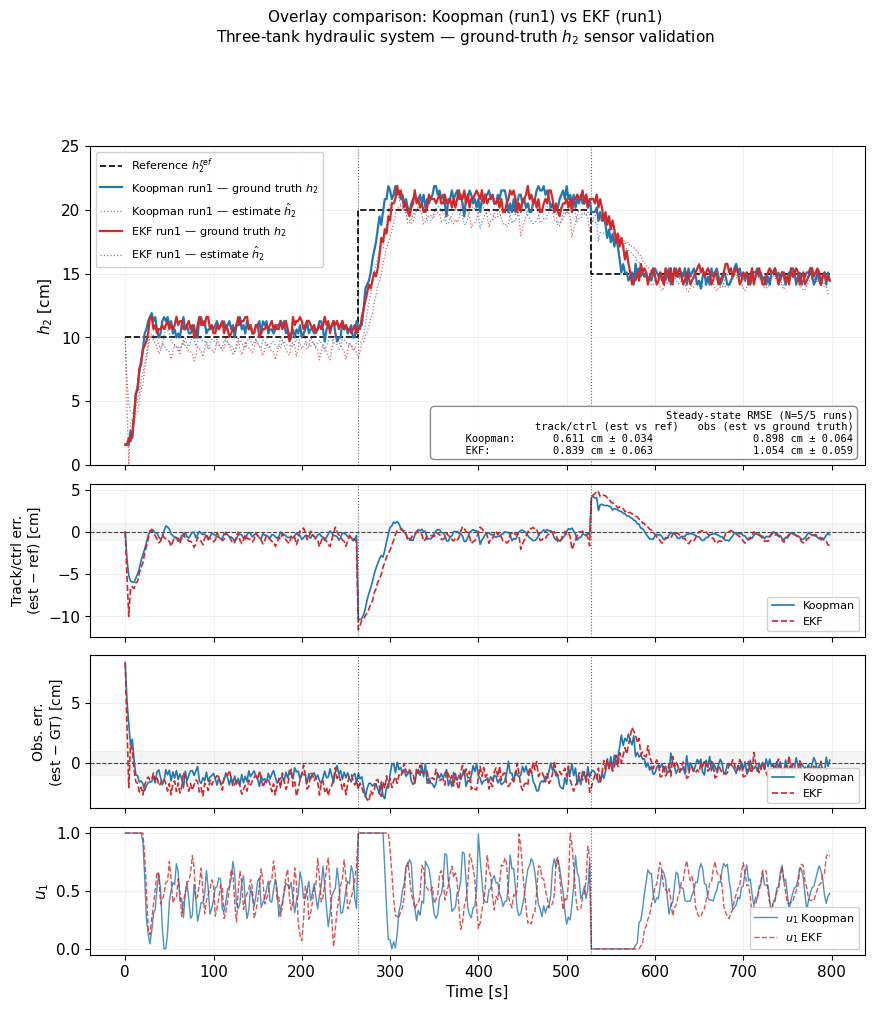

✓ Figura guardada en img/overlay_best_runs.png


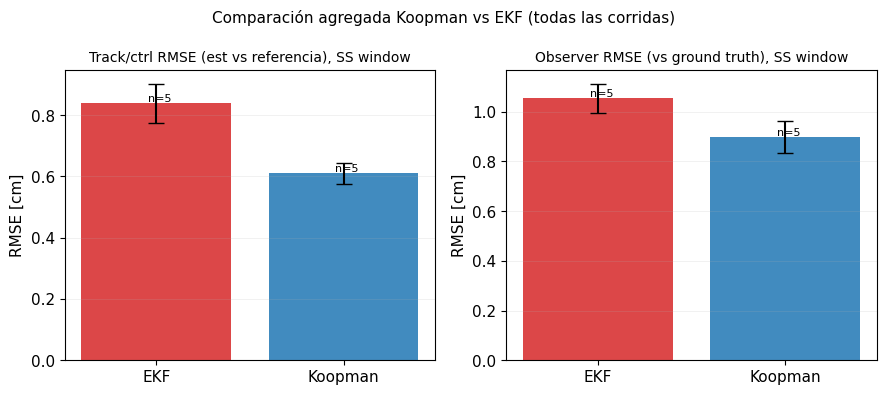

✓ Figura guardada en img/comparacion_agregada.png


In [8]:
"""
analizar_experimentos.py
========================
Analiza los CSV de los experimentos Koopman y EKF del artículo/tesis
(planta física de tres tanques) y genera figuras + tabla comparativa,
usando el sensor de verdad de terreno (h2_real_m) como referencia de
comparación tanto para el error de observación como para el error de
seguimiento de control.

Uso:
    Colocar este notebook/script en el mismo directorio que los CSV
    y ejecutar todas las celdas.

Estructura esperada de archivos (en el mismo directorio):
    koopman_run1.csv ... koopman_run5.csv   (5 corridas Koopman)
    ekf_run1.csv      ... ekf_run5.csv       (5 corridas EKF)

Columnas CSV — Koopman:
    t_s, h1_meas_m, h2_est_m, h2_real_m, error_obs_cm, h3_meas_m, ref_m, u1, u3

Columnas CSV — EKF:
    t_s, h1_meas_m, h1_ekf_m, h2_ekf_m, sigma_h2_m, h2_real_m, error_obs_cm,
    h3_meas_m, h3_ekf_m, ref_m, u1, u3

Notas:
    - h2_real_m es la lectura del sensor de verdad de terreno (h2), agregado
      recientemente. NO se usa como entrada del observador/controlador;
      solo se usa aquí, post-hoc, para validar la estimación (h2_est_m /
      h2_ekf_m) y el desempeño real de seguimiento de referencia (ref_m).
    - error_obs_cm ya viene calculado en los CSV como (h2_est - h2_real)*100.
    - Antes se comparaban 3 corridas por método; ahora son 5.
"""

import glob
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ═══════════════════════════════════════════════════════════════════════════
# 0) Directorio de datos
# ═══════════════════════════════════════════════════════════════════════════
# Carpeta donde están los CSV. Por defecto, la carpeta desde la que se
# ejecuta el notebook (cwd). Si tus CSV están en otra carpeta (p. ej. en
# VS Code el cwd suele ser la carpeta del workspace, no la del notebook),
# cambia CSV_DIR por la ruta correcta, por ejemplo:
#   CSV_DIR = r"C:\Users\PC\Downloads\datos_experimentos"
CSV_DIR = "."

# ═══════════════════════════════════════════════════════════════════════════
# 1) Carga y normalización de todas las corridas disponibles
# ═══════════════════════════════════════════════════════════════════════════

def _run_number(path):
    m = re.search(r"run(\d+)", os.path.basename(path))
    return int(m.group(1)) if m else -1

def cargar_corridas(patron):
    """Carga y ordena por número de corrida todos los CSV que matcheen el patrón."""
    archivos = sorted(glob.glob(os.path.join(CSV_DIR, patron)), key=_run_number)
    corridas = {}
    for f in archivos:
        df = pd.read_csv(f)
        df.columns = df.columns.str.strip()
        # Normalizar nombre de la columna de estimación a "h2_est_m"
        for alias in ["h2_koop_m", "h2_ekf_m", "h2_m"]:
            if alias in df.columns:
                df.rename(columns={alias: "h2_est_m"}, inplace=True)
        corridas[_run_number(f)] = df
    return corridas

koop_runs = cargar_corridas("koopman_run*.csv")
ekf_runs  = cargar_corridas("ekf_run*.csv")

if not koop_runs or not ekf_runs:
    cwd = os.path.abspath(CSV_DIR)
    archivos_presentes = sorted(os.listdir(cwd))
    raise FileNotFoundError(
        "No se encontraron los CSV esperados en:\n"
        f"    {cwd}\n\n"
        f"Corridas Koopman encontradas: {sorted(koop_runs.keys()) or 'ninguna'}\n"
        f"Corridas EKF encontradas:     {sorted(ekf_runs.keys()) or 'ninguna'}\n\n"
        f"Archivos presentes en esa carpeta ({len(archivos_presentes)}):\n"
        f"    {archivos_presentes}\n\n"
        "Revisa que:\n"
        "  1) Los CSV se llamen exactamente 'koopman_runN.csv' y 'ekf_runN.csv'.\n"
        "  2) CSV_DIR (arriba) apunte a la carpeta donde están esos archivos.\n"
        "     El directorio de trabajo actual de este notebook es:\n"
        f"     {os.getcwd()}"
    )

print(f"Directorio de datos: {os.path.abspath(CSV_DIR)}")
print(f"Corridas Koopman encontradas: {sorted(koop_runs.keys())}")
print(f"Corridas EKF encontradas:     {sorted(ekf_runs.keys())}")

# ═══════════════════════════════════════════════════════════════════════════
# 2) Métricas por corrida (ventana de estado estacionario auto-detectada)
# ═══════════════════════════════════════════════════════════════════════════

SS_T_START      = 400.0  # s — inicio del régimen permanente (idéntico a los scripts en vivo)
REF_CHANGE_2_S  = 528.0  # s — segunda transición de referencia
SS_EXCLUDE_S    = 60.0   # s — ventana excluida tras esa transición

def ventana_estado_estacionario(df):
    """Máscara booleana de estado estacionario — MISMA definición que
    koopman_real_plant.py / ekf_koopman_real.py / analizar_experimentos.py:
    t > 400s, excluyendo los 60s posteriores al cambio de referencia en t=528s."""
    t = df["t_s"].values
    mask = (t > SS_T_START) & ~((t >= REF_CHANGE_2_S) & (t < REF_CHANGE_2_S + SS_EXCLUDE_S))
    return mask

def metricas_corrida(df):
    """Calcula RMSE de observación (est vs verdad de terreno) y RMSE de
    control/seguimiento (estimación vs referencia — misma definición que
    "e_h2_ctrl"/"e_ctrl" en koopman_real_plant.py / ekf_koopman_real.py),
    en cm, tanto en régimen transitorio+EE (todo el registro) como solo en EE."""
    h2_est  = df["h2_est_m"].values * 100
    h2_real = df["h2_real_m"].values * 100
    ref     = df["ref_m"].values * 100

    err_obs   = h2_est - h2_real   # error del observador vs verdad de terreno
    err_track = h2_est - ref       # error de control (lo que "ve" el controlador)

    ss = ventana_estado_estacionario(df)

    def rmse(x):
        return float(np.sqrt(np.mean(x ** 2)))

    return {
        "obs_rmse_full_cm":   rmse(err_obs),
        "obs_rmse_ss_cm":     rmse(err_obs[ss]),
        "track_rmse_full_cm": rmse(err_track),
        "track_rmse_ss_cm":   rmse(err_track[ss]),
    }

def tabla_metricas(runs, metodo):
    filas = []
    for n, df in sorted(runs.items()):
        m = metricas_corrida(df)
        m["run"] = n
        m["metodo"] = metodo
        filas.append(m)
    return pd.DataFrame(filas)

tabla_koop = tabla_metricas(koop_runs, "Koopman")
tabla_ekf  = tabla_metricas(ekf_runs, "EKF")
tabla_todo = pd.concat([tabla_koop, tabla_ekf], ignore_index=True)

cols_orden = ["metodo", "run", "obs_rmse_ss_cm", "track_rmse_ss_cm",
              "obs_rmse_full_cm", "track_rmse_full_cm"]
print("\n=== Métricas por corrida ===")
print(tabla_todo[cols_orden].round(4).to_string(index=False))

# ═══════════════════════════════════════════════════════════════════════════
# 3) Resumen agregado (media ± desviación estándar entre las N corridas)
# ═══════════════════════════════════════════════════════════════════════════

resumen = tabla_todo.groupby("metodo").agg(
    n_corridas=("run", "count"),
    obs_rmse_ss_mean=("obs_rmse_ss_cm", "mean"),
    obs_rmse_ss_std=("obs_rmse_ss_cm", "std"),
    track_rmse_ss_mean=("track_rmse_ss_cm", "mean"),
    track_rmse_ss_std=("track_rmse_ss_cm", "std"),
).round(4)
print("\n=== Resumen agregado (media ± std, ventana EE) ===")
print(resumen.to_string())

os.makedirs("results", exist_ok=True)
tabla_todo[cols_orden].round(4).to_csv("results/metricas_por_corrida.csv", index=False)
resumen.to_csv("results/resumen_agregado.csv")
print("\n✓ Tablas guardadas en results/metricas_por_corrida.csv y results/resumen_agregado.csv")

# ═══════════════════════════════════════════════════════════════════════════
# 4) Selección de corrida representativa por método (menor RMSE de
#    seguimiento en EE) para la figura de overlay
# ═══════════════════════════════════════════════════════════════════════════

def mejor_corrida(runs, tabla):
    n_best = tabla.loc[tabla["track_rmse_ss_cm"].idxmin(), "run"]
    return int(n_best), runs[int(n_best)]

n_koop_best, df_koop = mejor_corrida(koop_runs, tabla_koop)
n_ekf_best,  df_ekf  = mejor_corrida(ekf_runs, tabla_ekf)
print(f"\nCorrida representativa Koopman: run{n_koop_best}"
      f"  |  Corrida representativa EKF: run{n_ekf_best}")

m_koop = metricas_corrida(df_koop)
m_ekf  = metricas_corrida(df_ekf)

t_k, t_e = df_koop["t_s"].values, df_ekf["t_s"].values
h2est_k, h2est_e = df_koop["h2_est_m"].values * 100, df_ekf["h2_est_m"].values * 100
h2real_k, h2real_e = df_koop["h2_real_m"].values * 100, df_ekf["h2_real_m"].values * 100
ref_k, ref_e = df_koop["ref_m"].values * 100, df_ekf["ref_m"].values * 100
errobs_k, errobs_e = h2est_k - h2real_k, h2est_e - h2real_e
errtrk_k, errtrk_e = h2est_k - ref_k, h2est_e - ref_e

# ═══════════════════════════════════════════════════════════════════════════
# 5) Figura de overlay (4 paneles): trayectoria real vs referencia,
#    error de seguimiento, error de observación (vs verdad de terreno), u1
# ═══════════════════════════════════════════════════════════════════════════

FONTSIZE = 11
plt.rcParams.update({"font.size": FONTSIZE})

fig, axes = plt.subplots(
    4, 1, figsize=(10, 10.5),
    gridspec_kw={"height_ratios": [2.5, 1.2, 1.2, 1]},
    sharex=True
)
fig.subplots_adjust(hspace=0.10)

COLOR_K = "#1f77b4"
COLOR_E = "#d62728"
COLOR_R = "black"

seg_bounds = sorted(np.unique(np.r_[0, np.where(np.diff(df_koop["ref_m"].values) != 0)[0] + 1,
                                     len(df_koop) - 1]))
tc_list = [t_k[i] for i in seg_bounds[1:-1]]

# ── Panel 1: trayectoria (verdad de terreno, sólida) + estimación (punteada) ──
ax1 = axes[0]
ax1.step(t_k, ref_k, where="post", color=COLOR_R, lw=1.2, ls="--",
          label="Reference $h_2^{ref}$", zorder=2)
ax1.plot(t_k, h2real_k, color=COLOR_K, lw=1.6, zorder=3,
          label=f"Koopman run{n_koop_best} — ground truth $h_2$")
ax1.plot(t_k, h2est_k, color=COLOR_K, lw=0.9, ls=":", alpha=0.75, zorder=3,
          label=f"Koopman run{n_koop_best} — estimate $\\hat{{h}}_2$")
ax1.plot(t_e, h2real_e, color=COLOR_E, lw=1.6, ls="-", zorder=3,
          label=f"EKF run{n_ekf_best} — ground truth $h_2$")
ax1.plot(t_e, h2est_e, color=COLOR_E, lw=0.9, ls=":", alpha=0.75, zorder=3,
          label=f"EKF run{n_ekf_best} — estimate $\\hat{{h}}_2$")

for tc in tc_list:
    ax1.axvline(tc, color=COLOR_R, lw=0.8, ls=":", alpha=0.6)

ax1.set_ylabel("$h_2$ [cm]", fontsize=FONTSIZE)
ax1.set_ylim(0, 25)
ax1.grid(alpha=0.25, lw=0.5)
ax1.legend(fontsize=FONTSIZE - 3, loc="upper left", framealpha=0.9, ncol=1)

stats_text = (
    "Steady-state RMSE (N={}/{} runs)\n"
    "                track/ctrl (est vs ref)   obs (est vs ground truth)\n"
    "  Koopman:      {:.3f} cm{}                {:.3f} cm{}\n"
    "  EKF:          {:.3f} cm{}                {:.3f} cm{}"
).format(
    len(koop_runs), len(ekf_runs),
    resumen.loc["Koopman", "track_rmse_ss_mean"],
    f" ± {resumen.loc['Koopman', 'track_rmse_ss_std']:.3f}" if len(koop_runs) > 1 else "",
    resumen.loc["Koopman", "obs_rmse_ss_mean"],
    f" ± {resumen.loc['Koopman', 'obs_rmse_ss_std']:.3f}" if len(koop_runs) > 1 else "",
    resumen.loc["EKF", "track_rmse_ss_mean"],
    f" ± {resumen.loc['EKF', 'track_rmse_ss_std']:.3f}" if len(ekf_runs) > 1 else "",
    resumen.loc["EKF", "obs_rmse_ss_mean"],
    f" ± {resumen.loc['EKF', 'obs_rmse_ss_std']:.3f}" if len(ekf_runs) > 1 else "",
)
ax1.text(0.985, 0.03, stats_text, transform=ax1.transAxes,
          fontsize=FONTSIZE - 3.5, family="monospace",
          va="bottom", ha="right",
          bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", alpha=0.92))

# ── Panel 2: error de seguimiento real (planta vs referencia) ──
ax2 = axes[1]
ax2.axhline(0, color=COLOR_R, lw=0.8, ls="--", alpha=0.7)
ax2.plot(t_k, errtrk_k, color=COLOR_K, lw=1.2, label="Koopman")
ax2.plot(t_e, errtrk_e, color=COLOR_E, lw=1.2, ls="--", label="EKF")
ax2.axhspan(-1, 1, alpha=0.08, color="gray", zorder=1)
for tc in tc_list:
    ax2.axvline(tc, color=COLOR_R, lw=0.8, ls=":", alpha=0.6)
ax2.set_ylabel("Track/ctrl err.\n(est $-$ ref) [cm]", fontsize=FONTSIZE - 1)
ax2.grid(alpha=0.25, lw=0.5)
ax2.legend(fontsize=FONTSIZE - 3, loc="lower right", framealpha=0.9)

# ── Panel 3: error de observación (estimación vs verdad de terreno) ──
ax3 = axes[2]
ax3.axhline(0, color=COLOR_R, lw=0.8, ls="--", alpha=0.7)
ax3.plot(t_k, errobs_k, color=COLOR_K, lw=1.2, label="Koopman")
ax3.plot(t_e, errobs_e, color=COLOR_E, lw=1.2, ls="--", label="EKF")
ax3.axhspan(-1, 1, alpha=0.08, color="gray", zorder=1)
for tc in tc_list:
    ax3.axvline(tc, color=COLOR_R, lw=0.8, ls=":", alpha=0.6)
ax3.set_ylabel("Obs. err.\n(est $-$ GT) [cm]", fontsize=FONTSIZE - 1)
ax3.grid(alpha=0.25, lw=0.5)
ax3.legend(fontsize=FONTSIZE - 3, loc="lower right", framealpha=0.9)

# ── Panel 4: señal de control u1 ──
ax4 = axes[3]
ax4.plot(t_k, df_koop["u1"].values, color=COLOR_K, lw=1.0, alpha=0.8, label="$u_1$ Koopman")
ax4.plot(t_e, df_ekf["u1"].values,  color=COLOR_E, lw=1.0, alpha=0.8, ls="--", label="$u_1$ EKF")
for tc in tc_list:
    ax4.axvline(tc, color=COLOR_R, lw=0.8, ls=":", alpha=0.6)
ax4.set_ylabel("$u_1$", fontsize=FONTSIZE)
ax4.set_xlabel("Time [s]", fontsize=FONTSIZE)
ax4.set_ylim(-0.05, 1.05)
ax4.grid(alpha=0.25, lw=0.5)
ax4.legend(fontsize=FONTSIZE - 3, loc="lower right", framealpha=0.9)

fig.suptitle(
    f"Overlay comparison: Koopman (run{n_koop_best}) vs EKF (run{n_ekf_best})\n"
    "Three-tank hydraulic system — ground-truth $h_2$ sensor validation",
    fontsize=FONTSIZE, y=1.01
)

os.makedirs("img", exist_ok=True)
plt.savefig("img/overlay_best_runs.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("✓ Figura guardada en img/overlay_best_runs.png")

# ═══════════════════════════════════════════════════════════════════════════
# 6) Figura de barras: comparación agregada entre métodos (N corridas)
# ═══════════════════════════════════════════════════════════════════════════

fig2, (bx1, bx2) = plt.subplots(1, 2, figsize=(9, 4))

for bx, col_mean, col_std, titulo in [
    (bx1, "track_rmse_ss_mean", "track_rmse_ss_std", "Track/ctrl RMSE (est vs referencia), SS window"),
    (bx2, "obs_rmse_ss_mean", "obs_rmse_ss_std", "Observer RMSE (vs ground truth), SS window"),
]:
    metodos = resumen.index.tolist()
    medias = resumen[col_mean].values
    stds = resumen[col_std].fillna(0).values
    colores = [COLOR_K if m == "Koopman" else COLOR_E for m in metodos]
    bx.bar(metodos, medias, yerr=stds, capsize=6, color=colores, alpha=0.85)
    bx.set_ylabel("RMSE [cm]")
    bx.set_title(titulo, fontsize=FONTSIZE - 1)
    bx.grid(alpha=0.25, lw=0.5, axis="y")
    for i, (m_, v) in enumerate(zip(metodos, medias)):
        n_runs = resumen.loc[m_, "n_corridas"]
        bx.text(i, v, f"  n={int(n_runs)}", ha="center", va="bottom", fontsize=FONTSIZE - 3)

fig2.suptitle("Comparación agregada Koopman vs EKF (todas las corridas)", fontsize=FONTSIZE)
fig2.tight_layout()
plt.savefig("img/comparacion_agregada.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("✓ Figura guardada en img/comparacion_agregada.png")
